<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>Ensemble Techniques and Model Tuning</font></center>

<center><img src="https://images.pexels.com/photos/7235894/pexels-photo-7235894.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" width="800" height="500"></center>

<center><font size=6>Visa Approval Facilitation</font></center>

# **Problem Statement**

## Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

## Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Note: This is a sample solution for the project. Projects will NOT be graded on the basis of how well the submission matches this sample solution. Projects will be graded on the basis of the rubric only.

# **Importing necessary libraries**

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 xgboost==3.0.5 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [ ]:
from google.colab import drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from sklearn.compose import ColumnTransformer

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Loading the dataset**

In [ ]:
data_set = pd.read_csv('....../EasyVisa.csv')

NameError: name 'pd' is not defined

# **Overview of the Dataset**

* Observations

* Sanity checks

In [ ]:
data_set.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [ ]:
data_set.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


Observations:

---
* 75% of the people has a prevailing_wage less than 107735.512500
* the biggesst prevailing_wage is 319210.270000
* 75% of the peple start working before 2005 and the newest employee is in 2016
* The nom pf empoyees has negative data


In [ ]:
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


In [ ]:
data_set.columns

Index(['case_id', 'continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'yr_of_estab',
       'region_of_employment', 'prevailing_wage', 'unit_of_wage',
       'full_time_position', 'case_status'],
      dtype='object')

In [ ]:
data_set.shape

(25480, 12)

Observations

---
* Data does not have nulls
* we have 12 columns and 25480 rows
* case_id is not needed
* case_status is the dependant variable





# <a name='link2'>**Exploratory Data Analysis (EDA)**</a>

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**

What is the distribution of visa case statuses (certified vs. denied)?


1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

In [ ]:
# Takes a feature and groups the data
# divide each group by the _case_status and plot it
def bar_case_status_vs_feature(feature, label_rotation = 0, dataset=data_set):
    # Grouping the data by the feature and calculating normalized counts (percentages)
    vs_personal_loan = dataset.groupby(feature, observed=True)['case_status'].value_counts(normalize=True).mul(100).reset_index(name='percentage')
    # showing diagram
    plot = sns.barplot(data=vs_personal_loan, x=feature, y='percentage', hue='case_status')
    if label_rotation:
        plot.set_xticklabels(plot.get_xticklabels(), rotation=label_rotation, ha="right")
    plt.ylabel('Percentage') # Set y-axis label to 'Percentage'
    plt.show()

<Axes: xlabel='case_status', ylabel='count'>

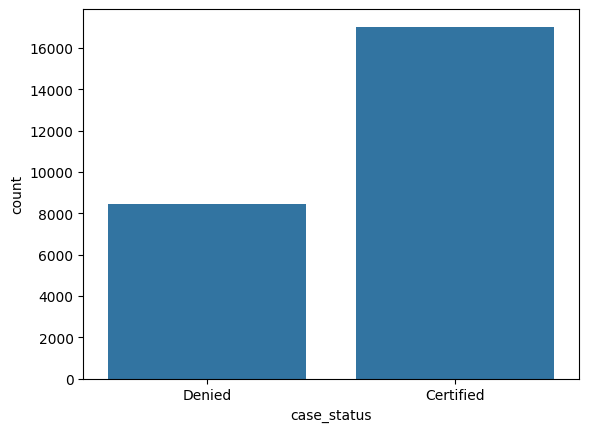

In [ ]:
sns.countplot(x='case_status', data=data_set)

Observation

---


the data seems not to be balanced

<Axes: xlabel='education_of_employee', ylabel='count'>

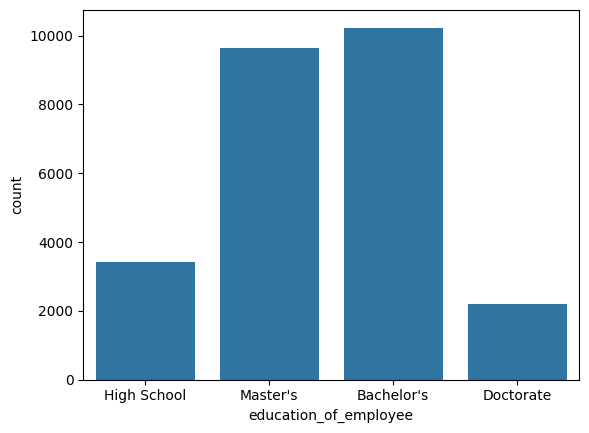

In [ ]:
sns.countplot(x='education_of_employee', data=data_set)

Observations:

---
Seems like we have more Master and Bachellors


<Axes: xlabel='has_job_experience', ylabel='count'>

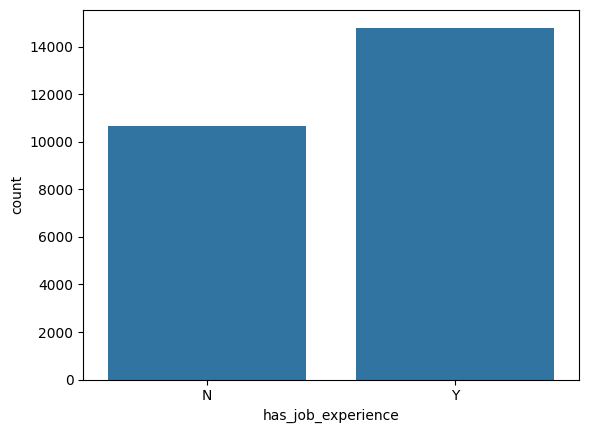

In [ ]:
sns.countplot(x='has_job_experience', data=data_set)

<Axes: xlabel='region_of_employment', ylabel='count'>

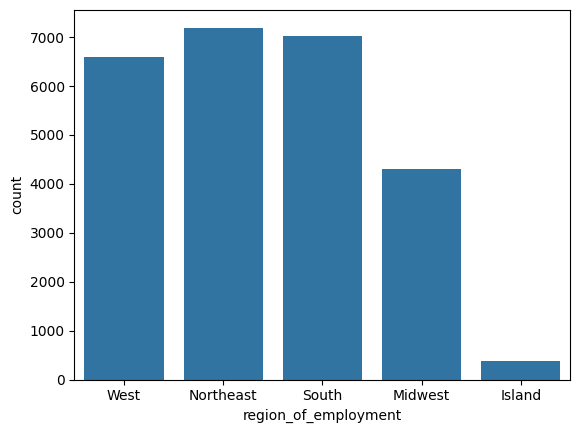

In [ ]:
sns.countplot(x='region_of_employment', data=data_set)

Observations:

---
* We do not have North
* The island and midwest are the regions that have less request being the Islands with less requests.
* It seems the other regions are very balanced


<Axes: xlabel='prevailing_wage'>

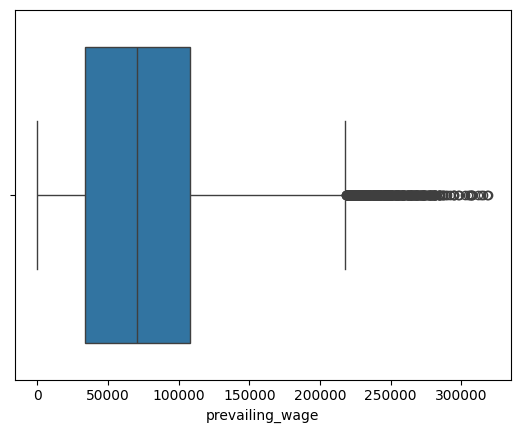

In [ ]:
sns.boxplot(x=data_set['prevailing_wage'])

Observations:

---
75% of the people has a wage lower than 120000


## Bivariate analysis


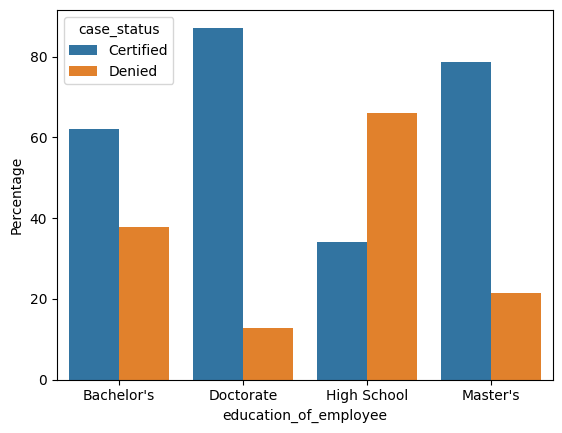

In [ ]:
bar_case_status_vs_feature('education_of_employee')

Observations:

---
It seems the higest the level of education more probability the person has to be certified.




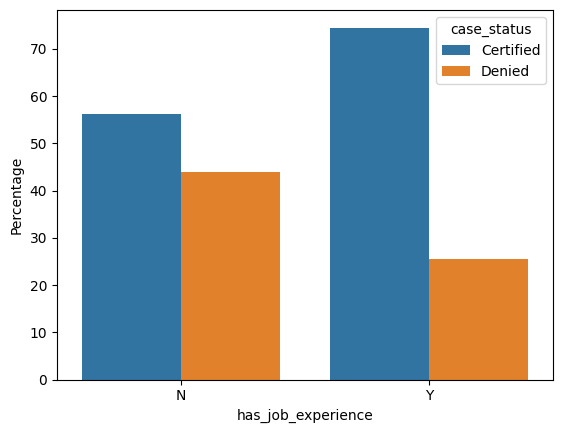

In [ ]:
bar_case_status_vs_feature('has_job_experience')

Observations

---
seems the experience affects the probability the person gets the certification. Having job experience makes it easier.


<Axes: xlabel='prevailing_wage', ylabel='case_status'>

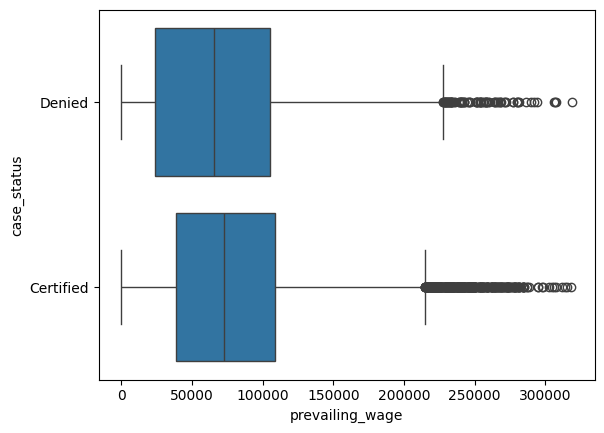

In [ ]:
sns.boxplot(x=data_set['prevailing_wage'], y=data_set['case_status'])

Observation:

---

It does not seems  like the prevailing has a storng impact on the data. they look very similar

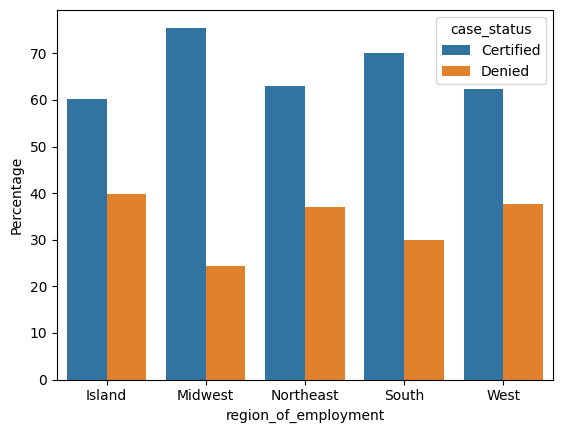

In [ ]:
bar_case_status_vs_feature('region_of_employment')

Observations

---
* It seems the midwest region has more approval than other  but we need to concider the midwest is one of the sectors that have less candidates.
* By the other hand the South region is the second place in approvals and requests by region.


<Axes: xlabel='no_of_employees', ylabel='case_status'>

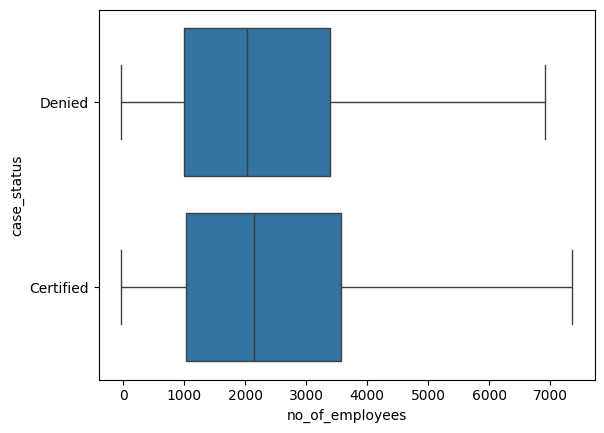

In [ ]:
sns.boxplot(x=data_set['no_of_employees'], y=data_set['case_status'], showfliers=False)

observations


---
I can not see that the size of the company is too relevant to get an approval even if the bigger companies have a little advantage it is not a big advante over small companies.


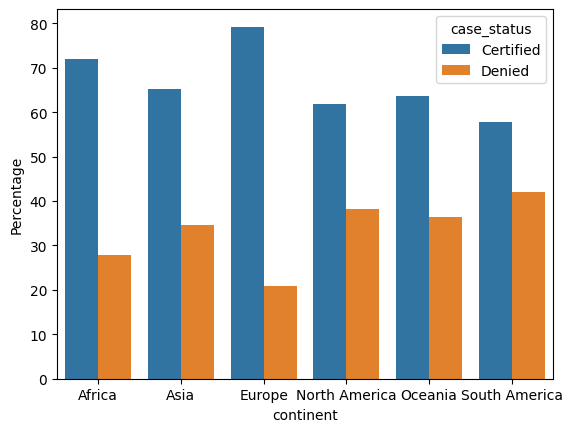

In [ ]:
bar_case_status_vs_feature('continent')

Observations:

---
* Europe is the countinent that has more certified.
* Africa is the second place in certified
* THe lowest rate of certified people is South America


<Axes: >

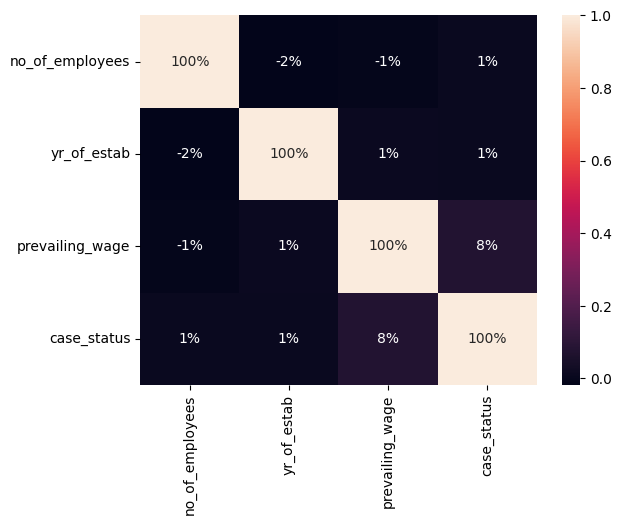

In [ ]:
data_set_2 = data_set.copy()
data_set_2['case_status'] = data_set_2['case_status'].map({'Certified': 1, 'Denied': 0})
numeric_cols = data_set_2.select_dtypes(include='number').corr()
sns.heatmap(numeric_cols, annot=True, fmt='.0%')

# **Data Pre-processing**

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

### Misning value treatement

In [ ]:
data_set.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


Observations:

---
The data set does not have missing values


### Feature engineering

In [ ]:
data_set = data_set.drop('case_id', axis=1)

In [ ]:
# checking how many number of employees are not positive
data_set[data_set['no_of_employees'] <= 0]
# assuming # of employees are not correctly typed and transforming it to positive
data_set['no_of_employees'] = data_set['no_of_employees'].apply(lambda x: abs(x))
data_set[data_set['no_of_employees'] <= 0].count()

,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0
full_time_position,0


In [ ]:
"""
moves from  string values to boolean usuing the map
"""
def to_boolean(feature, df, bool_map={'Y': 1, 'N': 0}):
  df[feature] = df[feature].map(bool_map)

In [ ]:
data_set.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [ ]:
#create a new data frame name df that will have the new converted values
df = data_set.copy()
#transform the job experience and requesting job colums from Y to boolean values
to_boolean('has_job_experience', df)
to_boolean('requires_job_training', df)
to_boolean('full_time_position', df)


In [ ]:
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,0,0,14513,2007,West,592.2029,Hour,1,Denied
1,Asia,Master's,1,0,2412,2002,Northeast,83425.6500,Year,1,Certified
2,Asia,Bachelor's,0,1,44444,2008,West,122996.8600,Year,1,Denied
3,Asia,Bachelor's,0,0,98,1897,West,83434.0300,Year,1,Denied
4,Africa,Master's,1,0,1082,2005,South,149907.3900,Year,1,Certified


In [ ]:
# separating the independ variable and the rest
# getting the features matrix
X = df.drop('case_status', axis=1)
# getting the target vector and transforming it to numerical values
y = df['case_status'].map({'Certified': 1, 'Denied': 0})
X.head(5)

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position
0,Asia,High School,0,0,14513,2007,West,592.2029,Hour,1
1,Asia,Master's,1,0,2412,2002,Northeast,83425.6500,Year,1
2,Asia,Bachelor's,0,1,44444,2008,West,122996.8600,Year,1
3,Asia,Bachelor's,0,0,98,1897,West,83434.0300,Year,1
4,Africa,Master's,1,0,1082,2005,South,149907.3900,Year,1


Observations:

---
We needed the data divided in test and split because we need it to be split to use the encode that will dummy encode some columns


In [ ]:
# splitting my data set with the same proportion as the one in the original dataset, with stratify yes because we do not have balanced data in some features
X_temp, X_test, y_temp, y_test = train_test_split( X, y, test_size=0.2, random_state=5, stratify=y )

# then we split the temporary set into train and validation
X_train, X_val, y_train, y_val = train_test_split(  X_temp, y_temp, test_size=0.2, random_state=5, stratify=y_temp)
# printing the training set shape and porportion
print('------TRAIN-----')
print(X_train.shape, y_train.shape)
print(100* y_train.value_counts(normalize=True))
# printing the test set shape and proportion
print('\n------TEST-----')
print(X_test.shape, y_test.shape)
print(100* y_test.value_counts(normalize=True))
print('\n------VALIDATION-----')
print(X_val.shape, y_val.shape)
print(100* y_test.value_counts(normalize=True))

------TRAIN-----
(16307, 10) (16307,)
case_status
1    66.787269
0    33.212731
Name: proportion, dtype: float64

------TEST-----
(5096, 10) (5096,)
case_status
1    66.797488
0    33.202512
Name: proportion, dtype: float64

------VALIDATION-----
(4077, 10) (4077,)
case_status
1    66.797488
0    33.202512
Name: proportion, dtype: float64


Observation

---
we are going to use this later as our features X and target vector y


In [ ]:
# Initialize the encoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
columns = ['continent', 'education_of_employee', 'region_of_employment', "unit_of_wage"]
enconder_setup = ('encoder',encoder, columns )

# creating encoder transform to transform the columns in dummy columns
ct = ColumnTransformer(transformers=[enconder_setup], remainder='passthrough')
ct.set_output(transform="pandas")
ct.verbose_feature_names_out = False

# executing the transformation
X_train_transformed = ct.fit_transform(X_train)
X_test_transformed = ct.transform(X_test)
X_validation_transformed = ct.transform(X_val)

# label encoder to pass from Denied Certified
labelEncoder = LabelEncoder()
y_train_transform = labelEncoder.fit_transform(y_train)
y_test_transform = labelEncoder.transform(y_test)
y_val_transform = labelEncoder.transform(y_val)


In [ ]:
X_validation_transformed.head()

,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,education_of_employee_Bachelor's,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,...,unit_of_wage_Hour,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,prevailing_wage,full_time_position
12507,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0,0,69615,2011,48743.46,1
22966,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0,1,2453,1994,178992.15,1
1942,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1,0,2950,1999,17916.46,1
9368,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0,0,670,1984,183952.23,0
5533,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1,0,146,1998,61635.37,1


In [ ]:
y_val_transform

array([1, 0, 1, ..., 1, 1, 1])

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

# **Model Building**

In [ ]:
data_set.columns

Index(['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'yr_of_estab',
       'region_of_employment', 'prevailing_wage', 'unit_of_wage',
       'full_time_position', 'case_status'],
      dtype='object')

In [ ]:
def evaluate_tree(y, prediction):
  # scoring the tree.
  recall =     recall_score(y, prediction)
  acc =        accuracy_score(y, prediction)
  precision =  precision_score(y, prediction)
  f1 =         f1_score(y, prediction)

  # printing the results.
  print(f'Accuracy:  {acc * 100:.2f}%')
  print(f'Recall: {recall * 100:.2f}%')
  print(f'Precision: {precision * 100:.2f}%')
  print(f'F1: {f1 * 100:.2f}%')

  confusion_matrix_prediction_train = confusion_matrix(y, prediction)
  #show hitmap of the confustion matrix
  print('Confusion Matrix:')
  print(confusion_matrix_prediction_train)
  return f1, acc

**Model can make wrong predictions as:**

* Predict someone will be certified but is Denied
* Predict Denied but is Certified

**Which case is more important?**

In this case both are important we can not have False Positives or negatives because the idea is to get drivers that influence if someone is True Positive and True Negative.

in other words the idea is to have a balanced model that measn check the F1 score and then getfrom the best f1 score the drivers of that model.

### Original Data

In [ ]:
#importing models libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, make_scorer;
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [ ]:
# Creating models dict
models = {
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1),
    "Random forest": RandomForestClassifier(random_state=1, class_weight='balanced'),
    "GBM": GradientBoostingClassifier(random_state=1),
    "Adaboost": AdaBoostClassifier(random_state=1),
    "dtree": DecisionTreeClassifier(random_state=1, class_weight='balanced')
}

In [ ]:
# creating results dict
position_obtect = {
    "name": None,
    "score": 0,
    "accurency": 0
  }
results = {}

In [ ]:
def order_places(first_place, second_place, new_place):
  # places the model if has lower f1 score

    # cases to take in count
    #First place: GBM with a f1 diff score of 0.78 and an accurency of 0.89
    #Second place: Adaboost with a f2 diff score of -0.41 and an accurency of -0.84

    #First place: GBM with a f1 diff score of -4.36 and an accurency of 0.98
    #Second place: Random forest with a f2 diff score of 26.20 and an accurency of 31.62

    if  (new_place["score"] < first_place["score"]) and first_place["score"] > 0 or first_place["score"] == 0:
      second_place = first_place.copy()
      first_place = new_place.copy()
    # handles when 2 scores ar negative ( selects too well ) and we need to decide by the accurency ( performance )
    elif new_place["score"] < 0 and abs(new_place["score"]) > abs(first_place["score"]):
      if (new_place["accurency"] > first_place["accurency"]):
          second_place = first_place.copy()
          first_place = new_place.copy()
      else:
        second_place = new_place.copy()

    elif (new_place["score"] < second_place["score"]) or second_place["score"] == 0:
      second_place = new_place.copy()

    return first_place, second_place

In [ ]:
def select_best_models(first_place, second_place):
  # trick to check if the scores are similar by rounding result to near number of 4 ( trying them to be the same number ) and abs to prevent negative numbers
  f1_diff_between_models = abs(abs(first_place["score"]) - abs(second_place["score"]))

  print(round(f1_diff_between_models,4))
  print(second_place["accurency"] > first_place["accurency"])

  # if they are round to similar number then the tie breaker is the accurancy of the model
  # if we have models too near 0.01 we check the accurency to be sure we choose the correct number

  if round(f1_diff_between_models,4) < 0.01 and (second_place["accurency"] > first_place["accurency"]) :
    # switching places
    first_place, second_place = second_place, first_place

  print(f"First place: {first_place["name"]} with a f1 diff score of {first_place["score"] * 100:.2f} and an accurency of {first_place["accurency"] * 100:.2f}" )
  print(f"Second place: {second_place["name"]} with a f2 diff score of {second_place["score"] * 100:.2f} and an accurency of {second_place["accurency"] * 100:.2f}")

  return first_place, second_place

In [ ]:
def run_model_in_validation_and_test(model_name, model, x_train_p, y_train_p, is_test=False):
  print("*"*50)
  print(f"Model: {model_name}")
  # executes the model in the train set
  predicted_model = model.predict(x_train_p)
  score_train, accurency_train = evaluate_tree(y_train_p, predicted_model)
  if not is_test:
    print("-"*50)
    print('VALIDATION')
    # executes the model in the validation set
    validation_predicted_model = model.predict(X_validation_transformed)
    score_validation, accurency_validation = evaluate_tree(y_val_transform, validation_predicted_model)

    # calculates the accurency and f1 scores diff between sets
    diff_score = score_train - score_validation
    accurency = accurency_train - accurency_validation
    print(f"f1 scores diff: {diff_score * 100:.2f}")
    return {
              "name": model_name,
              "score": diff_score,
              "accurency": accurency
            }

In [ ]:
def run_models(models, x_train_p, y_train_p, first_place, second_place, is_test=False ):
  # creates objects to save the info of first and second place
  scores_diff = 0

  # runs logic for each model
  for model_name in models.keys():

    # training the model
    model = models[model_name]
    model.fit(x_train_p, y_train_p)

    # executing the model
    new_model_results = run_model_in_validation_and_test(model_name, model, x_train_p, y_train_p, is_test)
    if not is_test:
      #checking if the model is one of the 2 best models by f1 and accurency
      first_place, second_place = order_places(first_place, second_place, new_model_results)

  print("*"*50)
  if not is_test:
    return select_best_models(first_place, second_place)
  # finding the winner between the ones we selected as the 2 best
  else:
    return first_place, second_place




In [ ]:
#executing model with original transformed data
first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models(models, X_train_transformed, y_train_transform, first_place, second_place)

results["original"] = {
    "first_place": first_place,
    "second_place": second_place
}

**************************************************
Model: Bagging
Accuracy:  98.60%
Recall: 98.77%
Precision: 99.12%
F1: 98.95%
Confusion Matrix:
[[ 5321    95]
 [  134 10757]]
--------------------------------------------------
VALIDATION
Accuracy:  70.17%
Recall: 77.89%
Precision: 77.55%
F1: 77.72%
Confusion Matrix:
[[ 740  614]
 [ 602 2121]]
f1 scores diff: 21.23
**************************************************
Model: Random forest
Accuracy:  99.99%
Recall: 99.99%
Precision: 100.00%
F1: 100.00%
Confusion Matrix:
[[ 5416     0]
 [    1 10890]]
--------------------------------------------------
VALIDATION
Accuracy:  73.04%
Recall: 83.88%
Precision: 77.58%
F1: 80.61%
Confusion Matrix:
[[ 694  660]
 [ 439 2284]]
f1 scores diff: 19.39
**************************************************
Model: GBM
Accuracy:  75.85%
Recall: 88.17%
Precision: 78.37%
F1: 82.98%
Confusion Matrix:
[[2766 2650]
 [1288 9603]]
--------------------------------------------------
VALIDATION
Accuracy:  74.96%
Recall:

Observations
The best is GMB beacuse the accurency of this model is better in both cases
the second place is the Adaboost because it is very good model the accurency is not as good as GBM

* First place: GBM with a f1 diff score of 0.78 and an accurency of 0.89
* Second place: Adaboost with a f2 diff score of -0.41 and an accurency of -0.84

In [ ]:
def execute_sample_function(sample_function, parameters, x_train_p, y_train_p):
  print("orignal 'Certified': {}".format(sum(y_train == 1)))
  print("original 'Denied': {} \n".format(sum(y_train == 0)))

  sm = sample_function( **parameters['conf'] )

  X_train_new, y_train_new = sm.fit_resample(X_train_transformed, y_train_transform)

  print(f"After {parameters["name"]},'Certified': { sum(y_train_new == 1) }")
  print(f"After {parameters["name"]}, 'Denied': { sum(y_train_new == 0) } \n")

  print("Resultin shpe X: {}".format(X_train_new.shape))
  print("Resulting shape y: {} \n".format(y_train_new.shape))
  return  X_train_new, y_train_new

###Oversampled Data

In [ ]:
params = {"name": "SMOTE",
          "conf": {
                    "sampling_strategy":1,
                    "k_neighbors":5,
                    "random_state":1
                   }
          }
X_train_over, y_train_over = execute_sample_function(SMOTE, params,X_train_transformed, y_train_transform)

orignal 'Certified': 10891
original 'Denied': 5416 

After SMOTE,'Certified': 10891
After SMOTE, 'Denied': 10891 

Resultin shpe X: (21782, 25)
Resulting shape y: (21782,) 



In [ ]:

first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models(models, X_train_over, y_train_over, first_place, second_place)

results["oversample"] = {
    "first_place": first_place,
    "second_place": second_place
}

**************************************************
Model: Bagging
Accuracy:  98.87%
Recall: 98.57%
Precision: 99.16%
F1: 98.86%
Confusion Matrix:
[[10800    91]
 [  156 10735]]
--------------------------------------------------
VALIDATION
Accuracy:  69.34%
Recall: 75.69%
Precision: 77.80%
F1: 76.73%
Confusion Matrix:
[[ 766  588]
 [ 662 2061]]
f1 scores diff: 22.13
**************************************************
Model: Random forest
Accuracy:  100.00%
Recall: 100.00%
Precision: 100.00%
F1: 100.00%
Confusion Matrix:
[[10891     0]
 [    0 10891]]
--------------------------------------------------
VALIDATION
Accuracy:  72.97%
Recall: 82.89%
Precision: 78.02%
F1: 80.38%
Confusion Matrix:
[[ 718  636]
 [ 466 2257]]
f1 scores diff: 19.62
**************************************************
Model: GBM
Accuracy:  81.06%
Recall: 85.37%
Precision: 78.60%
F1: 81.84%
Confusion Matrix:
[[8359 2532]
 [1593 9298]]
--------------------------------------------------
VALIDATION
Accuracy:  74.61%
Recal

After the Overfitting with SMOTE the results are the same in terms of which modesl fit the best but numbers are different for each model.
* First place: GBM with a f1 diff score of 0.24 and an accurency of 6.45
* Second place: Adaboost with a f2 diff score of -0.75 and an accurency of 5.64


###Undersampled Data


In [ ]:
# executing execute_sample_function for undersample
params = {"name": "RandomUnderSampler",
          "conf": {
                    "random_state":1
                   }
          }
X_train_un, y_train_un = execute_sample_function(RandomUnderSampler, params,X_train_transformed, y_train_transform)

orignal 'Certified': 10891
original 'Denied': 5416 

After RandomUnderSampler,'Certified': 5416
After RandomUnderSampler, 'Denied': 5416 

Resultin shpe X: (10832, 25)
Resulting shape y: (10832,) 



In [ ]:
first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models(models, X_train_un, y_train_un, first_place, second_place)

results["undersample"] = {
    "first_place": first_place,
    "second_place": second_place
}


**************************************************
Model: Bagging
Accuracy:  98.14%
Recall: 97.06%
Precision: 99.19%
F1: 98.11%
Confusion Matrix:
[[5373   43]
 [ 159 5257]]
--------------------------------------------------
VALIDATION
Accuracy:  65.49%
Recall: 61.55%
Precision: 82.32%
F1: 70.43%
Confusion Matrix:
[[ 994  360]
 [1047 1676]]
f1 scores diff: 27.68
**************************************************
Model: Random forest
Accuracy:  100.00%
Recall: 100.00%
Precision: 100.00%
F1: 100.00%
Confusion Matrix:
[[5416    0]
 [   0 5416]]
--------------------------------------------------
VALIDATION
Accuracy:  68.38%
Recall: 66.65%
Precision: 82.65%
F1: 73.80%
Confusion Matrix:
[[ 973  381]
 [ 908 1815]]
f1 scores diff: 26.20
**************************************************
Model: GBM
Accuracy:  72.21%
Recall: 73.67%
Precision: 71.58%
F1: 72.61%
Confusion Matrix:
[[3832 1584]
 [1426 3990]]
--------------------------------------------------
VALIDATION
Accuracy:  71.23%
Recall: 71.98

### Finding the best model

In [ ]:
import json
for model in results.items():
  print(json.dumps(model, indent=4, default=str))

[
    "original",
    {
        "first_place": {
            "name": "GBM",
            "score": 0.007815487619223127,
            "accurency": 0.008937853116012473
        },
        "second_place": {
            "name": "Adaboost",
            "score": -0.004123300620293757,
            "accurency": -0.008416958042865241
        }
    }
]
[
    "oversample",
    {
        "first_place": {
            "name": "GBM",
            "score": 0.002449892170239054,
            "accurency": 0.06448658521334116
        },
        "second_place": {
            "name": "Adaboost",
            "score": -0.0074546812042732835,
            "accurency": 0.056385000096953686
        }
    }
]
[
    "undersample",
    {
        "first_place": {
            "name": "GBM",
            "score": -0.043569230153539085,
            "accurency": 0.009831198107044914
        },
        "second_place": {
            "name": "Adaboost",
            "score": -0.05955090376210925,
            "accurency": -0.0053

Observations:

---
It is clear that the **Gradient Boosting** (GBM) is better than tha other modesl when we use the oversample technique with a good f1 score and a high accurancy, followed by the **Adaboost** under the overfiting data.
My third choice is going to be **Random forest** because litterute says that usually this model improves a lot when we tune it because of the modification of the max_depth


# **Model Performance Improvement**

## **Note**

1. Sample parameter grids have been provided to do necessary hyperparameter tuning. These sample grids are expected to provide a balance between model performance improvement and execution time. One can extend/reduce the parameter grid based on execution time and system configuration.
  - Please note that if the parameter grid is extended to improve the model performance further, the execution time will increase
2. The models chosen in this notebook are based on test runs. One can update the best models as obtained upon code execution and tune them for best performance.

- For Gradient Boosting:

```
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}
```

- For Adaboost:

```
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}
```

- For Bagging Classifier:

```
param_grid = {
    'max_samples': [0.8,0.9,1],
    'max_features': [0.7,0.8,0.9],
    'n_estimators' : [30,50,70],
}
```
- For Random Forest:

```
param_grid = {
    "n_estimators": [50,110,25],
    "min_samples_leaf": np.arange(1, 4),
    "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
    "max_samples": np.arange(0.4, 0.7, 0.1)
}
```

- For Decision Trees:

```
param_grid = {
    'max_depth': np.arange(2,6),
    'min_samples_leaf': [1, 4, 7],
    'max_leaf_nodes' : [10, 15],
    'min_impurity_decrease': [0.0001,0.001]
}
```

- For XGBoost:

```
param_grid={'n_estimators':np.arange(50,110,25),
            'scale_pos_weight':[1,2,5],
            'learning_rate':[0.01,0.1,0.05],
            'gamma':[1,3],
            'subsample':[0.7,0.9]
}
```


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV

### Gradient boost with oversample

In [ ]:
boosting_results = {}

In [ ]:
estimator_gb = GradientBoostingClassifier(random_state=1)

#parametesr from the begining of the section
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}

scorer = make_scorer(f1_score)

randomized_cv_gb = RandomizedSearchCV(estimator=estimator_gb, param_distributions=param_grid, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

randomized_cv_gb.fit(X_train_over,y_train_over)

print("parameters {} with CV score={}:" .format(randomized_cv_gb.best_params_,randomized_cv_gb.best_score_))

parameters {'subsample': 0.9, 'n_estimators': np.int64(75), 'max_features': 0.7, 'learning_rate': 0.1, 'init': AdaBoostClassifier(random_state=1)} with CV score=0.8119791776353343:


In [ ]:
grediant_boosting_model = GradientBoostingClassifier(**randomized_cv_gb.best_params_)

first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models({"grediant_boosting": grediant_boosting_model}
                                       , X_train_over, y_train_over, first_place, second_place)

boosting_results["grediant_boosting"] = {
    "first_place": first_place,
    "second_place": second_place
}

**************************************************
Model: grediant_boosting
Accuracy:  80.95%
Recall: 85.79%
Precision: 78.22%
F1: 81.83%
Confusion Matrix:
[[8289 2602]
 [1548 9343]]
--------------------------------------------------
VALIDATION
Accuracy:  74.54%
Recall: 84.61%
Precision: 78.82%
F1: 81.62%
Confusion Matrix:
[[ 735  619]
 [ 419 2304]]
f1 scores diff: 0.21
**************************************************
0.0021
False
First place: grediant_boosting with a f1 diff score of 0.21 and an accurency of 6.41
Second place: None with a f2 diff score of 0.00 and an accurency of 0.00


### AdaBoosting oversample


In [ ]:
estimator_ada = AdaBoostClassifier(random_state=1)

#parametesr from the begining of the section
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}

scorer = make_scorer(f1_score)

randomized_cv_ada = RandomizedSearchCV(estimator=estimator_ada, param_distributions=param_grid, n_jobs = -1, n_iter=50, scoring=scorer, cv=5, random_state=1)

randomized_cv_ada.fit(X_train_over, y_train_over)

print("parameters {} with CV score={}:" .format(randomized_cv_ada.best_params_,randomized_cv_ada.best_score_))

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 18 is smaller than n_iter=50. Running 18 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


parameters {'n_estimators': np.int64(100), 'learning_rate': 0.1, 'estimator': DecisionTreeClassifier(max_depth=3, random_state=1)} with CV score=0.8017361645201252:


In [ ]:
ada_model = AdaBoostClassifier(**randomized_cv_ada.best_params_)

first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models({"ada_model": ada_model}
                                       , X_train_over, y_train_over, first_place, second_place)

boosting_results["ada_boost"] = {
    "first_place": first_place,
    "second_place": second_place
}

**************************************************
Model: ada_model
Accuracy:  79.79%
Recall: 83.71%
Precision: 77.62%
F1: 80.55%
Confusion Matrix:
[[8262 2629]
 [1774 9117]]
--------------------------------------------------
VALIDATION
Accuracy:  73.80%
Recall: 82.74%
Precision: 79.02%
F1: 80.84%
Confusion Matrix:
[[ 756  598]
 [ 470 2253]]
f1 scores diff: -0.29
**************************************************
0.0029
False
First place: ada_model with a f1 diff score of -0.29 and an accurency of 5.98
Second place: None with a f2 diff score of 0.00 and an accurency of 0.00


### Random Forest with Oversample

In [ ]:

estimator_rf = RandomForestClassifier(random_state=1, oob_score=True, bootstrap=True)

parameters = {
    "max_depth": list(np.arange(5, 15, 5)),
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [3, 5, 7],
    "n_estimators": np.arange(10, 40, 10),
}

score = make_scorer(f1_score)

grid_obj = GridSearchCV(estimator_rf, parameters, scoring=score, cv=5, n_jobs=-1)
grid_obj = grid_obj.fit(X_train_over, y_train_over)

In [ ]:
random_model = grid_obj.best_estimator_

first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models({"random_model": random_model}
                                       , X_train_over, y_train_over, first_place, second_place)

boosting_results["random_model"] = {
    "first_place": first_place,
    "second_place": second_place
}

**************************************************
Model: random_model
Accuracy:  81.92%
Recall: 87.49%
Precision: 78.72%
F1: 82.87%
Confusion Matrix:
[[8316 2575]
 [1363 9528]]
--------------------------------------------------
VALIDATION
Accuracy:  75.23%
Recall: 85.75%
Precision: 78.97%
F1: 82.22%
Confusion Matrix:
[[ 732  622]
 [ 388 2335]]
f1 scores diff: 0.66
**************************************************
0.0066
False
First place: random_model with a f1 diff score of 0.66 and an accurency of 6.69
Second place: None with a f2 diff score of 0.00 and an accurency of 0.00


# **Model Comparison and Final Model Selection**

In [ ]:
import json
for model in boosting_results.items():
  print(json.dumps(model, indent=4, default=str))

[
    "grediant_boosting",
    {
        "first_place": {
            "name": "grediant_boosting",
            "score": 0.002116370501374809,
            "accurency": 0.06407468372296243
        },
        "second_place": {
            "name": null,
            "score": 0,
            "accurency": 0
        }
    }
]
[
    "ada_boost",
    {
        "first_place": {
            "name": "ada_model",
            "score": -0.002900697026068766,
            "accurency": 0.05981794041957944
        },
        "second_place": {
            "name": null,
            "score": 0,
            "accurency": 0
        }
    }
]
[
    "random_model",
    {
        "first_place": {
            "name": "random_model",
            "score": 0.0065548330427901424,
            "accurency": 0.06693969568048108
        },
        "second_place": {
            "name": null,
            "score": 0,
            "accurency": 0
        }
    }
]


Observations:


---
Seeing the rsult we can see that:
* Ada is out of the game because even it is good the accurancy is not the best.
* when you look at the other models they are very similar ( under 1% ) and you have to go and check the other results to see which is the real winner.


```
Forest
Accuracy:  75.23%
F1: 82.22%
```

```
Gradiant
Accuracy:  74.42%
F1: 81.40%
```

```
Ada
Accuracy:  73.80%
F1: 80.84%
```

checking the table of the results the better in balance and with bettter performance is **Random Forest**.




### Running model on test

In [ ]:
random_model = grid_obj.best_estimator_

first_place = position_obtect.copy()
second_place = position_obtect.copy()

first_place, second_place = run_models({"random_model": random_model}
                                       , X_test_transformed, y_test_transform, first_place, second_place, True)

**************************************************
Model: random_model
Accuracy:  78.89%
Recall: 93.83%
Precision: 78.67%
F1: 85.58%
Confusion Matrix:
[[ 826  866]
 [ 210 3194]]
**************************************************


/tmp/ipython-input-627194338.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=90)


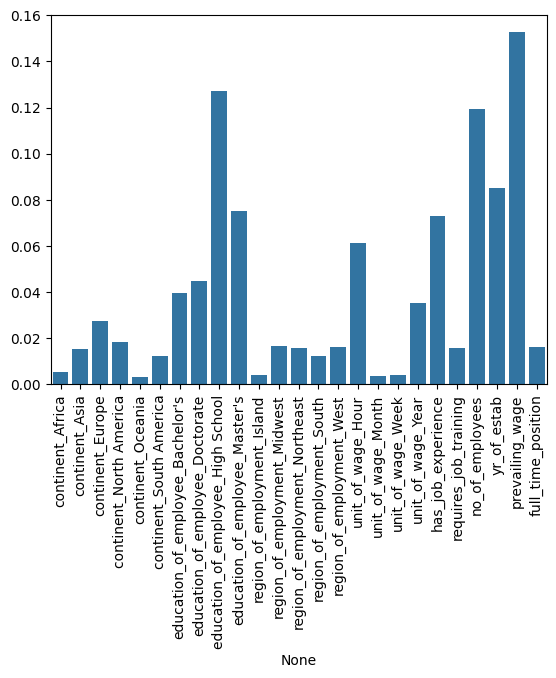

In [ ]:
# get the feature importance
feature_importances = pd.Series(random_model.feature_importances_, index=X_test_transformed.columns)
feature_importances.sort_values(ascending=False)
#plot the series and adjust the lables
plot = sns.barplot(x=feature_importances.index, y=feature_importances.values)
plot.set_xticklabels(plot.get_xticklabels(), rotation=90)
plt.show()


# **Actionable Insights and Recommendations**

___

After running the models and analyzing the data.

seeing the model we can say that The dominance of Prevailing Wage, Education, and Company Size suggests a model that prioritizes economic impact and applicant qualification. Minor features, such as specific continents or regions, have relatively low importance, indicating that the model is making

The profile that tend to get certified are:

* The applicant brings value to the country is the single most important factor.

* Advanced Educational Background: is very important effect.Having a Master's or Doctorate significantly strengthens the profile compared to those with only a Bachelor's or no degree.

* Proven Experience: Applicants with prior job experience have better oportunity to be certified, than those without experience

* Institutional Stability: When the sponsor company has high number of employees and has been established for many years. Tat also has a lot of weight in the certification.




